<h1>Tugas Kelompok Berbasis Kasus 01</h1> 

**IF25-31020 Pembelajaran Mesin (2025/2026)**

**Anggota Kelompok Coba-coba:**  
1. Christopher Leon Saputra (124140097)  
2. Erhan Kurniawan (124140217)  

**Dataset:** Medical Insurance Cost Dataset (Kaggle: `mosapabdelghany/medical-insurance-cost-dataset`)

**Cakupan:** tugas regresi (prediksi `charges`) dan tugas klasifikasi (prediksi `smoker`)
menggunakan Linear/Logistic Regression sebagai baseline, Support Vector Machine, dan
Artificial Neural Network (MLP). Seluruh preprocessing dilakukan bebas *data leakage*:
scaler di-fit hanya pada data latih, seleksi hyperparameter memakai cross-validation
pada data latih, dan test set disentuh satu kali di akhir.

# Import Library dan Pengaturan Device

In [1]:
import torch, torch.nn as nn, torch.nn.functional as func
import matplotlib.pyplot as plt, seaborn as sns
import numpy as np, pandas as pd
import os, glob, copy, random, zipfile

from torch.utils.data import DataLoader
from sklearn import preprocessing
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import (classification_report, confusion_matrix, mean_absolute_error,
                             mean_squared_error, r2_score, f1_score)
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.svm import SVR, SVC
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyClassifier

torch.manual_seed(42); np.random.seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

Using device: cpu


# Data Loading
Dataset dibaca dari folder `./data`. Jika file zip hasil unduhan Kaggle ada tetapi
belum diekstrak, ekstraksi dilakukan dengan modul `zipfile` bawaan Python agar
berjalan di Windows maupun Linux/Colab.

In [2]:
# Opsional (butuh kaggle.json): !kaggle datasets download -d mosapabdelghany/medical-insurance-cost-dataset -p ./data
ZIP = "./data/medical-insurance-cost-dataset.zip"
if os.path.exists(ZIP) and not glob.glob("./data/*.csv"):
    os.makedirs("./data", exist_ok=True)
    with zipfile.ZipFile(ZIP) as z:
        z.extractall("./data")

csv_files = glob.glob("./data/*.csv")
print(csv_files)
dataset = pd.read_csv(csv_files[0])
dataset

['./data\\insurance.csv']


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


# Exploratory Data Analysis (EDA)
Tujuan: mengenal distribusi target, keseimbangan kelas, dan hubungan antar fitur
sebelum memilih model dan metrik.

In [3]:
print("Ukuran dataset:", dataset.shape)
print("\nTipe data:\n", dataset.dtypes)
print("\nMissing value:\n", dataset.isnull().sum())
print("\nData duplikat:", dataset.duplicated().sum())

Ukuran dataset: (1338, 7)

Tipe data:
 age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object

Missing value:
 age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Data duplikat: 1


In [4]:
dataset.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


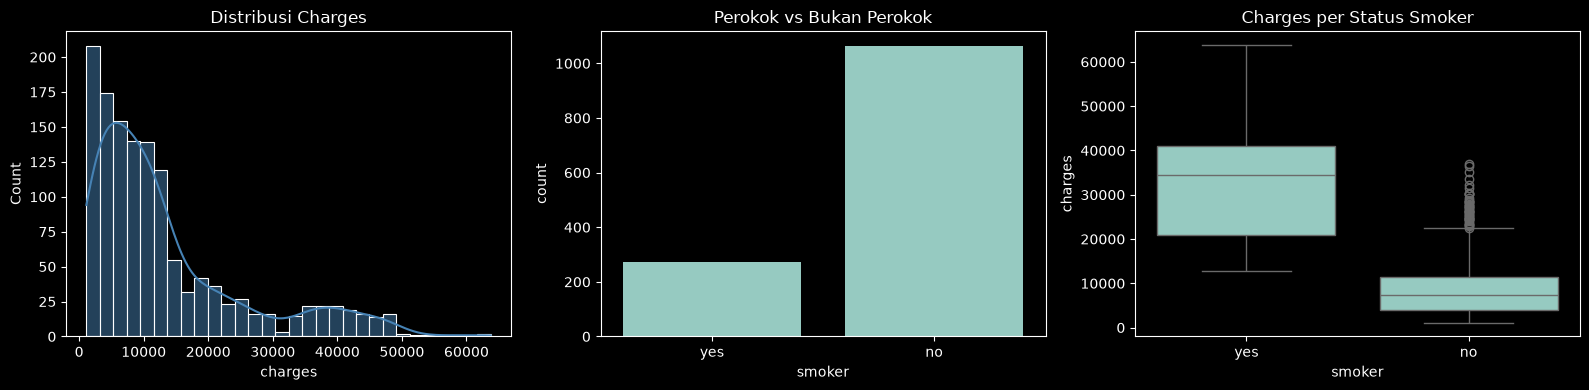

In [5]:
# Distribusi target regresi (charges) dan target klasifikasi (smoker)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(dataset['charges'], kde=True, ax=ax[0], color='steelblue'); 
ax[0].set_title('Distribusi Charges')
sns.countplot(x='smoker', data=dataset, ax=ax[1]); 
ax[1].set_title('Perokok vs Bukan Perokok')
sns.boxplot(x='smoker', y='charges', data=dataset, ax=ax[2]); 
ax[2].set_title('Charges per Status Smoker')
plt.tight_layout(); plt.show()

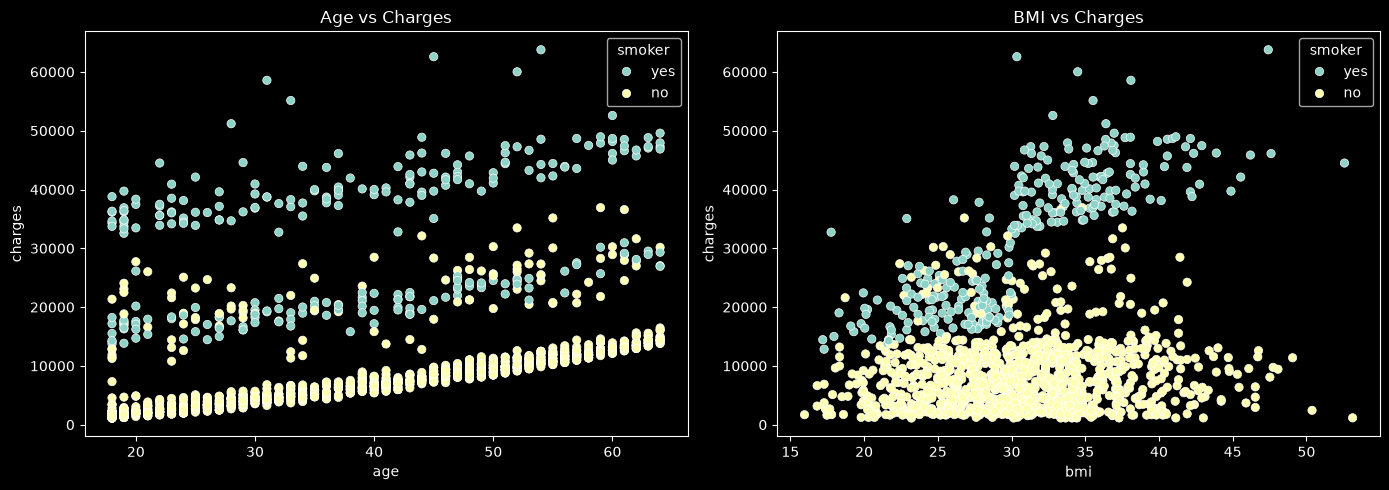

In [6]:
# Hubungan umur & BMI terhadap charges, diwarnai status smoker
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x='age', y='charges', hue='smoker', data=dataset, ax=ax[0]); 
ax[0].set_title('Age vs Charges')
sns.scatterplot(x='bmi', y='charges', hue='smoker', data=dataset, ax=ax[1]); 
ax[1].set_title('BMI vs Charges')
plt.tight_layout(); 
plt.show()

## Analisis EDA
- Distribusi `charges` miring ke kanan (right-skewed): mean $13.270,42$ 
  lebih besar daripada median $9.382,03$, artinya sebagian kecil
  individu berbiaya sangat tinggi menarik mean ke atas.
- Kelas `smoker` tidak seimbang: $274$ perokok vs
  $1.063$ bukan perokok (sekitar 20% minoritas). Karena itu pada
  tugas klasifikasi metrik utama adalah precision, recall, dan $F_1$ kelas `yes`,
  bukan accuracy semata.
- Boxplot dan scatter menunjukkan biaya perokok jauh lebih tinggi, dan pada perokok
  dengan BMI > 30 biaya melonjak tajam → indikasi kuat adanya **interaksi**
  `smoker` $\times$ `bmi` yang akan dipakai sebagai fitur rekayasa pada tugas regresi.
- Tidak ada missing value; terdapat $1$ baris duplikat yang
  akan dibuang pada tahap persiapan data.

# Data Preparation
- `sex` dan `smoker` biner → label encoding $\{0,1\}$.
- `region` bersifat **nominal** (tidak punya urutan), sehingga dipakai one-hot encoding
  dengan `dtype=int`; label encoding biasa akan menciptakan urutan palsu
  (northeast < northwest < ...) yang menyesatkan model berbasis jarak seperti SVM/ANN.
- Fitur rekayasa: `obese` $= \mathbb{1}[bmi \ge 30]$ dan interaksi
  `smoker_bmi` $= smoker \times bmi$.
- **Aturan kebocoran:** fitur yang diturunkan dari `smoker` hanya boleh masuk tugas
  **regresi**. Pada tugas klasifikasi (target = `smoker`) fitur tersebut dilarang,
  karena nilainya positif tepat ketika `smoker = 1` sehingga target bocor ke fitur.
- Dua dataframe disiapkan: `data_reg` (dengan interaksi) dan `data_clf` (tanpa interaksi).

In [7]:
# Menghapus duplikat jika ada
dataset = dataset.drop_duplicates().reset_index(drop=True)

# Konversi kolom kategorikal ke numerik (label encoding seperti pada modul)
def encode(df, with_interaction):
    df = df.copy()
    for c in ['sex', 'smoker']:
        df[c] = preprocessing.LabelEncoder().fit_transform(df[c])
    df = pd.get_dummies(df, columns=['region'], dtype=int)
    df['obese'] = (df['bmi'] >= 30).astype(int)
    if with_interaction:
        df['smoker_bmi'] = df['smoker'] * df['bmi']
    return df

data_reg = encode(dataset, True)
data_clf = encode(dataset, False)
print("Fitur regresi  :", list(data_reg.columns))
print("Fitur klasif.  :", list(data_clf.columns))

Fitur regresi  : ['age', 'sex', 'bmi', 'children', 'smoker', 'charges', 'region_northeast', 'region_northwest', 'region_southeast', 'region_southwest', 'obese', 'smoker_bmi']
Fitur klasif.  : ['age', 'sex', 'bmi', 'children', 'smoker', 'charges', 'region_northeast', 'region_northwest', 'region_southeast', 'region_southwest', 'obese']


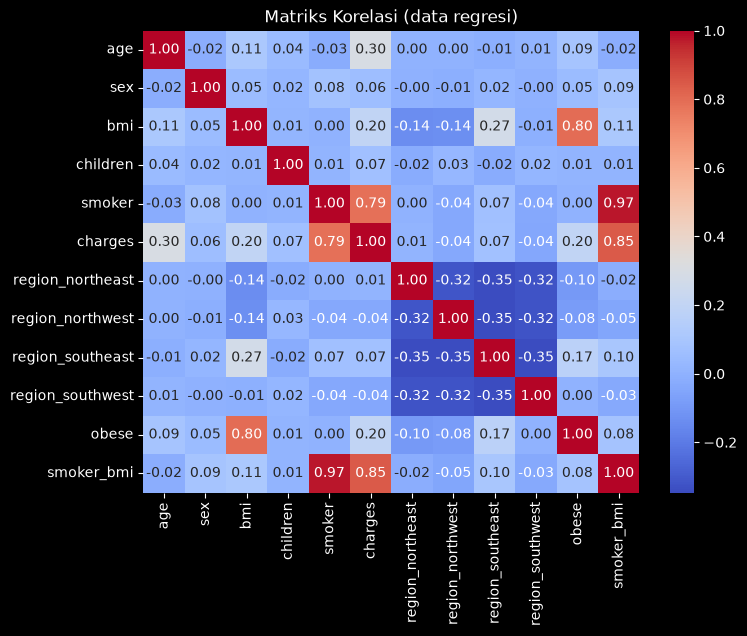

In [8]:
# Korelasi antar fitur
plt.figure(figsize=(8, 6))
sns.heatmap(data_reg.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Matriks Korelasi (data regresi)'); plt.show()

# BAGIAN A - TUGAS REGRESI (Prediksi `charges`)

## Pembagian Data dan Penskalaan
- Split 1: 70% train+val (935 baris) vs 30% test (402 baris), `random_state=5`,
  stratified terhadap `smoker` agar proporsi perokok sama di semua porsi.
- Split 2: 80/20 dari train+val → train 748 baris, validation 187 baris.
  Validation hanya dipakai ANN (early stopping & seleksi konfigurasi).
  SVR dan Linear memakai 5-fold CV pada seluruh 935 baris train+val.
- Penskalaan fitur (fit hanya pada train):
  min-max $x' = \dfrac{x - x_{min}}{x_{max} - x_{min}}$;
  target distandarkan $z = \dfrac{y - \mu_{train}}{\sigma_{train}}$ agar training SVR/MLP stabil.
- Metrik laporan:
  $\mathrm{MAE} = \frac{1}{n}\sum_i |y_i - \hat{y}_i|$,
  $\mathrm{RMSE} = \sqrt{\frac{1}{n}\sum_i (y_i - \hat{y}_i)^2}$,
  $R^2 = 1 - \frac{\sum_i (y_i - \hat{y}_i)^2}{\sum_i (y_i - \bar{y})^2}$.
  Metrik seleksi model selama tuning: **RMSE** (selaras dengan $R^2$/RMSE di tabel).

In [9]:
X_reg, y_reg = data_reg.drop(columns=['charges']), data_reg['charges']

X_trval_r, X_te_r, y_trval_r, y_te_r = train_test_split(
    X_reg, y_reg, test_size=0.3, random_state=5, stratify=X_reg['smoker'])
X_tr_r, X_vl_r, y_tr_r, y_vl_r = train_test_split(
    X_trval_r, y_trval_r, test_size=0.2, random_state=5, stratify=X_trval_r['smoker'])

# Normalisasi fitur (fit hanya pada data train agar tidak terjadi data leakage)
sc_Xr = preprocessing.MinMaxScaler().fit(X_tr_r)
X_tr_r_sc = pd.DataFrame(sc_Xr.transform(X_tr_r), columns=X_reg.columns)
X_vl_r_sc = pd.DataFrame(sc_Xr.transform(X_vl_r), columns=X_reg.columns)
X_te_r_sc = pd.DataFrame(sc_Xr.transform(X_te_r), columns=X_reg.columns)

# Target juga dinormalisasi untuk SVR dan MLP agar training stabil
sc_yr = preprocessing.StandardScaler().fit(y_tr_r.values.reshape(-1, 1))
y_tr_r_s = sc_yr.transform(y_tr_r.values.reshape(-1, 1)).ravel()
y_vl_r_s = sc_yr.transform(y_vl_r.values.reshape(-1, 1)).ravel()
print(f"Regresi train/val/test: {X_tr_r.shape[0]}/{X_vl_r.shape[0]}/{X_te_r.shape[0]}")

Regresi train/val/test: 748/187/402


In [10]:
# Fungsi bantu untuk menghitung metrik regresi
reg_results = {}
def eval_regression(name, y_true, y_pred):
    mae, rmse = mean_absolute_error(y_true, y_pred), np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    reg_results[name] = {'MAE': round(mae, 2), 'RMSE': round(rmse, 2), 'R2': round(r2, 4)}
    print(f"{name} -> MAE: {mae:,.2f} | RMSE: {rmse:,.2f} | R2: {r2:.4f}")

## Model 1 - Linear Regression (baseline)
$\hat{y} = \beta_0 + \sum_j \beta_j x_j$. OLS tanpa regularisasi bersifat invariant
terhadap penskalaan fitur, sehingga model dilatih langsung pada data mentah
(train+val, 935 baris) agar setara dengan SVR/SVM. Dua versi dilatih: fitur dasar
(tanpa `obese` dan `smoker_bmi`) dan fitur lengkap, supaya kontribusi rekayasa fitur
terlihat sebagai selisih $R^2$ keduanya.

In [11]:
cols_basic = ['age', 'sex', 'bmi', 'children', 'smoker'] + [c for c in X_reg.columns if c.startswith('region_')]

lin_basic = LinearRegression().fit(X_trval_r[cols_basic], y_trval_r)
eval_regression("Linear (fitur dasar)", y_te_r, lin_basic.predict(X_te_r[cols_basic]))

lin_full = LinearRegression().fit(X_trval_r, y_trval_r)
eval_regression("Linear (fitur lengkap)", y_te_r, lin_full.predict(X_te_r))
print("Koefisien fitur lengkap ($/satuan):", dict(zip(X_reg.columns, lin_full.coef_.round(2))))

Linear (fitur dasar) -> MAE: 4,267.05 | RMSE: 6,336.91 | R2: 0.7388
Linear (fitur lengkap) -> MAE: 3,008.09 | RMSE: 5,119.06 | R2: 0.8296
Koefisien fitur lengkap ($/satuan): {'age': np.float64(257.91), 'sex': np.float64(-457.08), 'bmi': np.float64(-178.68), 'children': np.float64(533.93), 'smoker': np.float64(-19335.96), 'region_northeast': np.float64(747.04), 'region_northwest': np.float64(422.31), 'region_southeast': np.float64(-289.3), 'region_southwest': np.float64(-880.04), 'obese': np.float64(3255.96), 'smoker_bmi': np.float64(1406.95)}


## Model 2 - Support Vector Regression (SVR)
SVR meminimumkan $\frac{1}{2}\|w\|^2 + C\sum_i(\xi_i + \xi_i^*)$ dengan kendala
$|y_i - w^\top x_i - b| \le \epsilon + \xi_i$ (*epsilon-insensitive loss*).
$C$ mengontrol trade-off margin vs error; $\epsilon$ (dalam satuan standar deviasi
karena target distandarkan) menentukan lebar zona toleransi.
Penskalaan fitur dan target dibungkus `Pipeline` + `TransformedTargetRegressor`
sehingga scaler di-fit ulang di setiap fold CV (bebas leakage) dan prediksi
otomatis kembali ke satuan dollar. Grid dipisah per kernel agar tidak ada kombinasi
parameter yang tidak bermakna (mis. `gamma` untuk kernel linear).

In [12]:
grid_svr = [
    {'svr__regressor__kernel': ['rbf'], 'svr__regressor__C': [1, 10, 100, 1000],
     'svr__regressor__gamma': ['scale', 0.003, 0.01, 0.03, 0.1], 'svr__regressor__epsilon': [0.01, 0.1, 0.2]},
    {'svr__regressor__kernel': ['poly'], 'svr__regressor__C': [1, 10, 100, 1000],
     'svr__regressor__gamma': ['scale', 0.01, 0.1], 'svr__regressor__degree': [2, 3], 'svr__regressor__epsilon': [0.01, 0.1, 0.2]},
    {'svr__regressor__kernel': ['linear'], 'svr__regressor__C': [1, 10, 100, 1000], 'svr__regressor__epsilon': [0.01, 0.1, 0.2]},
]
pipe_svr = Pipeline([
    ('scaler_X', preprocessing.MinMaxScaler()),
    ('svr', TransformedTargetRegressor(regressor=SVR(), transformer=preprocessing.StandardScaler()))])

cv_svr = GridSearchCV(pipe_svr, grid_svr, cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1)
cv_svr.fit(X_trval_r, y_trval_r)                      # CV pada 935 baris train+val
bp = cv_svr.best_params_
print("SVR terbaik:", bp, "| CV RMSE:", round(-cv_svr.best_score_, 2), "dollar")

y_pred_svr = cv_svr.best_estimator_.predict(X_te_r)   # test disentuh sekali
svr_lbl = f"SVR ({bp['svr__regressor__kernel']}, C={bp['svr__regressor__C']})"
eval_regression(svr_lbl, y_te_r, y_pred_svr)

SVR terbaik: {'svr__regressor__C': 10, 'svr__regressor__degree': 2, 'svr__regressor__epsilon': 0.1, 'svr__regressor__gamma': 'scale', 'svr__regressor__kernel': 'poly'} | CV RMSE: 4157.1 dollar
SVR (poly, C=10) -> MAE: 2,406.24 | RMSE: 4,722.19 | R2: 0.8550


## Model 3 - ANN (MLP) Regresi
Arsitektur: input $\to$ [Linear-ReLU-Dropout] $\times 2$ $\to$ Linear (output kontinu,
tanpa aktivasi). Loss $\mathrm{MSE} = \frac{1}{n}\sum(\hat{y}_i - y_i)^2$ pada target
terstandarkan; optimizer AdamW.
Pencarian konfigurasi: 12 konfigurasi acak (hidden 16/32/64, lr 0.001/0.003/0.01,
weight decay 0/1e-4/1e-3, dropout 0/0.1/0.2, batch 32/64), masing-masing 2 seed,
dipilih berdasarkan **RMSE validasi**. Konfigurasi terbaik kemudian dilatih ulang
dengan **5 seed**; early stopping (patience 25) memantau **loss validasi**, dan bobot
terbaik (bukan bobot epoch terakhir) yang disimpan. Hasil dilaporkan sebagai
rata-rata ± std antar seed serta satu baris ensemble (rata-rata prediksi).

In [13]:
class MLPReg(nn.Module):
    def __init__(self, inp, hid, drop):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(inp, hid), nn.ReLU(), nn.Dropout(drop),
            nn.Linear(hid, hid), nn.ReLU(), nn.Dropout(drop),
            nn.Linear(hid, 1))
    def forward(self, x): return self.net(x)

def train_reg(seed, cfg, Xtr, ytr, Xvl, yvl, save_hist=False):
    torch.manual_seed(seed); np.random.seed(seed)
    m = MLPReg(Xtr.shape[1], cfg['hid'], cfg['drop']).to(device)
    opt = torch.optim.AdamW(m.parameters(), lr=cfg['lr'], weight_decay=cfg['wd'])
    tr_dl = DataLoader(torch.utils.data.TensorDataset(
        torch.tensor(Xtr, dtype=torch.float32, device=device),
        torch.tensor(ytr, dtype=torch.float32, device=device)), batch_size=cfg['bs'], shuffle=True)
    vl_X = torch.tensor(Xvl, dtype=torch.float32, device=device)
    vl_y = torch.tensor(yvl, dtype=torch.float32, device=device)

    best_vl, best_st, bad = float('inf'), None, 0
    h_tr, h_vl = [], []
    for ep in range(300):
        m.train(); tot = 0.0
        for xb, yb in tr_dl:
            l = func.mse_loss(m(xb).reshape(-1), yb)
            opt.zero_grad(); l.backward(); opt.step(); tot += l.item()
        m.eval()
        with torch.inference_mode():
            vl = func.mse_loss(m(vl_X).reshape(-1), vl_y).item()
        if save_hist: h_tr.append(tot / len(tr_dl)); h_vl.append(vl)
        if vl < best_vl: best_vl, best_st, bad = vl, copy.deepcopy(m.state_dict()), 0
        else:
            bad += 1
            if bad >= 25: break
    m.load_state_dict(best_st)
    return m, (h_tr, h_vl) if save_hist else None

In [14]:
space = {'hid': [16, 32, 64], 'lr': [0.001, 0.003, 0.01], 'wd': [0, 1e-4, 1e-3],
         'drop': [0, 0.1, 0.2], 'bs': [32, 64]}
rng = random.Random(1)
configs_r = [{k: rng.choice(v) for k, v in space.items()} for _ in range(12)]

def val_rmse_r(m, X, y):
    m.eval()
    with torch.inference_mode():
        p = sc_yr.inverse_transform(m(torch.tensor(X, dtype=torch.float32, device=device)).cpu().numpy()).ravel()
    return np.sqrt(mean_squared_error(y, p))

Xtr_np, Xvl_np = X_tr_r_sc.values, X_vl_r_sc.values
best_cfg_r, best_sc_r = None, float('inf')
for i, cfg in enumerate(configs_r, 1):
    s = [val_rmse_r(train_reg(sd, cfg, Xtr_np, y_tr_r_s, Xvl_np, y_vl_r_s)[0], Xvl_np, y_vl_r) for sd in (42, 43)]
    if np.mean(s) < best_sc_r: best_sc_r, best_cfg_r = np.mean(s), cfg
    print(f"Config {i:2d} {cfg} -> val RMSE {np.mean(s):,.2f}")
print("Config terbaik:", best_cfg_r)

preds_r, hist_r42 = [], None
for sd in [42, 43, 44, 45, 46]:
    m, h = train_reg(sd, best_cfg_r, Xtr_np, y_tr_r_s, Xvl_np, y_vl_r_s, save_hist=(sd == 42))
    if sd == 42: hist_r42 = h
    m.eval()
    with torch.inference_mode():
        preds_r.append(sc_yr.inverse_transform(
            m(torch.tensor(X_te_r_sc.values, dtype=torch.float32, device=device)).cpu().numpy()).ravel())

maes  = [mean_absolute_error(y_te_r, p) for p in preds_r]
rmses = [np.sqrt(mean_squared_error(y_te_r, p)) for p in preds_r]
r2s   = [r2_score(y_te_r, p) for p in preds_r]
reg_results["MLP (rata-rata 5 seed)"] = {
    'MAE': f"{np.mean(maes):,.2f} ± {np.std(maes):,.2f}",
    'RMSE': f"{np.mean(rmses):,.2f} ± {np.std(rmses):,.2f}",
    'R2': f"{np.mean(r2s):.4f} ± {np.std(r2s):.4f}"}
y_pred_mlp_r = np.mean(preds_r, axis=0)
eval_regression("MLP (ensemble 5 seed)", y_te_r, y_pred_mlp_r)

Config  1 {'hid': 16, 'lr': 0.01, 'wd': 0, 'drop': 0.1, 'bs': 32} -> val RMSE 3,773.29
Config  2 {'hid': 32, 'lr': 0.003, 'wd': 0.0001, 'drop': 0.2, 'bs': 64} -> val RMSE 3,815.21
Config  3 {'hid': 16, 'lr': 0.001, 'wd': 0.0001, 'drop': 0, 'bs': 64} -> val RMSE 3,859.75
Config  4 {'hid': 32, 'lr': 0.01, 'wd': 0, 'drop': 0.2, 'bs': 64} -> val RMSE 3,805.69
Config  5 {'hid': 32, 'lr': 0.01, 'wd': 0, 'drop': 0.2, 'bs': 32} -> val RMSE 3,849.43
Config  6 {'hid': 32, 'lr': 0.001, 'wd': 0, 'drop': 0, 'bs': 32} -> val RMSE 3,858.53
Config  7 {'hid': 32, 'lr': 0.01, 'wd': 0, 'drop': 0.1, 'bs': 32} -> val RMSE 3,817.50
Config  8 {'hid': 64, 'lr': 0.001, 'wd': 0.0001, 'drop': 0.1, 'bs': 32} -> val RMSE 3,822.53
Config  9 {'hid': 32, 'lr': 0.001, 'wd': 0.001, 'drop': 0, 'bs': 64} -> val RMSE 3,871.38
Config 10 {'hid': 32, 'lr': 0.001, 'wd': 0.0001, 'drop': 0.2, 'bs': 32} -> val RMSE 3,849.69
Config 11 {'hid': 16, 'lr': 0.01, 'wd': 0.001, 'drop': 0.1, 'bs': 32} -> val RMSE 3,777.94
Config 12 {'hid

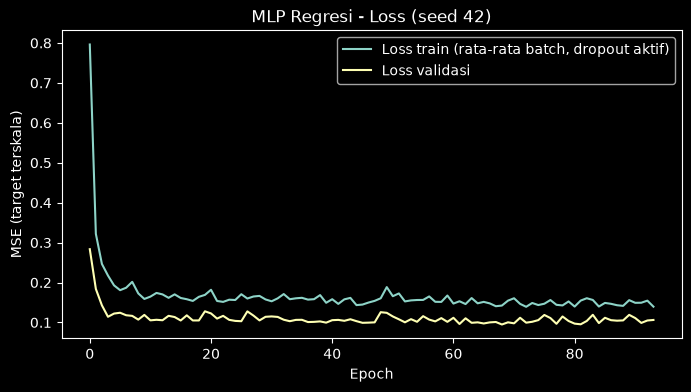

In [15]:
plt.figure(figsize=(8, 4))
plt.plot(hist_r42[0], label='Loss train (rata-rata batch, dropout aktif)')
plt.plot(hist_r42[1], label='Loss validasi')
plt.title('MLP Regresi - Loss (seed 42)'); plt.xlabel('Epoch'); plt.ylabel('MSE (target terskala)')
plt.legend(); plt.show()

                                     MAE              RMSE               R2
Linear (fitur dasar)             4267.05           6336.91           0.7388
Linear (fitur lengkap)           3008.09           5119.06           0.8296
SVR (poly, C=10)                 2406.24           4722.19            0.855
MLP (rata-rata 5 seed)  2,534.24 ± 92.53  4,882.47 ± 28.37  0.8450 ± 0.0018
MLP (ensemble 5 seed)            2437.34            4834.8            0.848


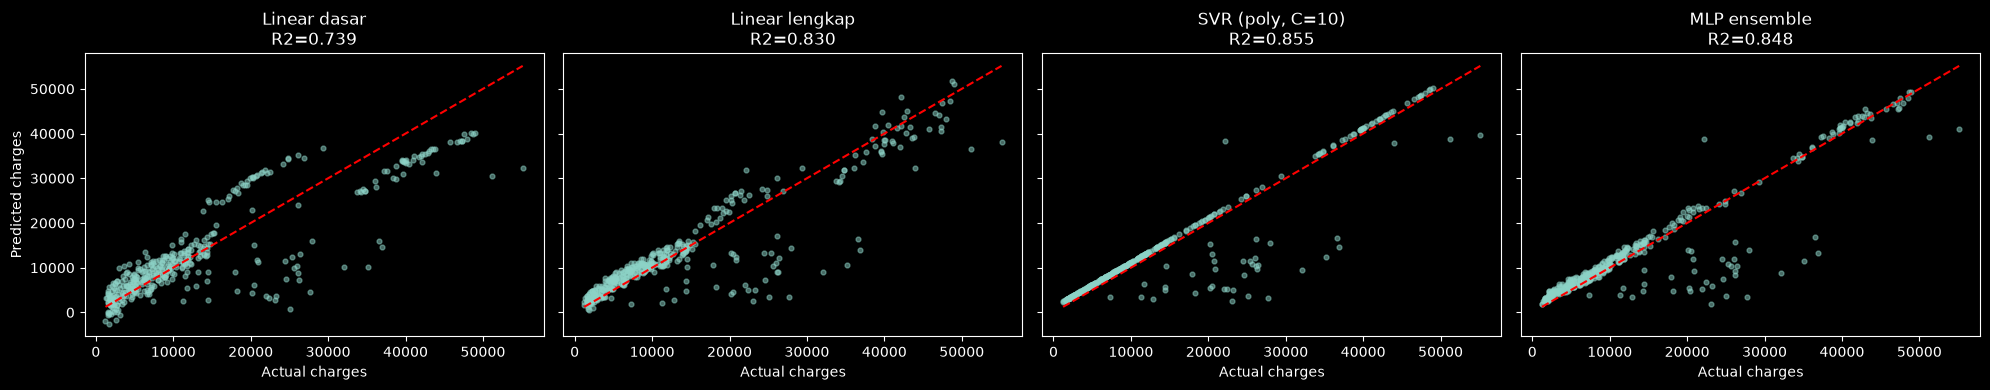

In [16]:
print(pd.DataFrame(reg_results).T.to_string())

fig, ax = plt.subplots(1, 4, figsize=(20, 4), sharey=True)
for a, (n, p) in zip(ax, [("Linear dasar", lin_basic.predict(X_te_r[cols_basic])),
                          ("Linear lengkap", lin_full.predict(X_te_r)),
                          (svr_lbl, y_pred_svr), ("MLP ensemble", y_pred_mlp_r)]):
    a.scatter(y_te_r, p, alpha=0.5, s=12)
    a.plot([y_te_r.min(), y_te_r.max()], [y_te_r.min(), y_te_r.max()], 'r--')
    a.set_title(f"{n}\nR2={r2_score(y_te_r, p):.3f}"); a.set_xlabel('Actual charges')
ax[0].set_ylabel('Predicted charges')
plt.tight_layout(); plt.show()

## Perbandingan Model Regresi

                                     MAE              RMSE               R2
Linear (fitur dasar)             4267.05           6336.91           0.7388
Linear (fitur lengkap)           3008.09           5119.06           0.8296
SVR (poly, C=10)                 2406.24           4722.19            0.855
MLP (rata-rata 5 seed)  2,534.24 ± 92.53  4,882.47 ± 28.37  0.8450 ± 0.0018
MLP (ensemble 5 seed)            2437.34            4834.8            0.848


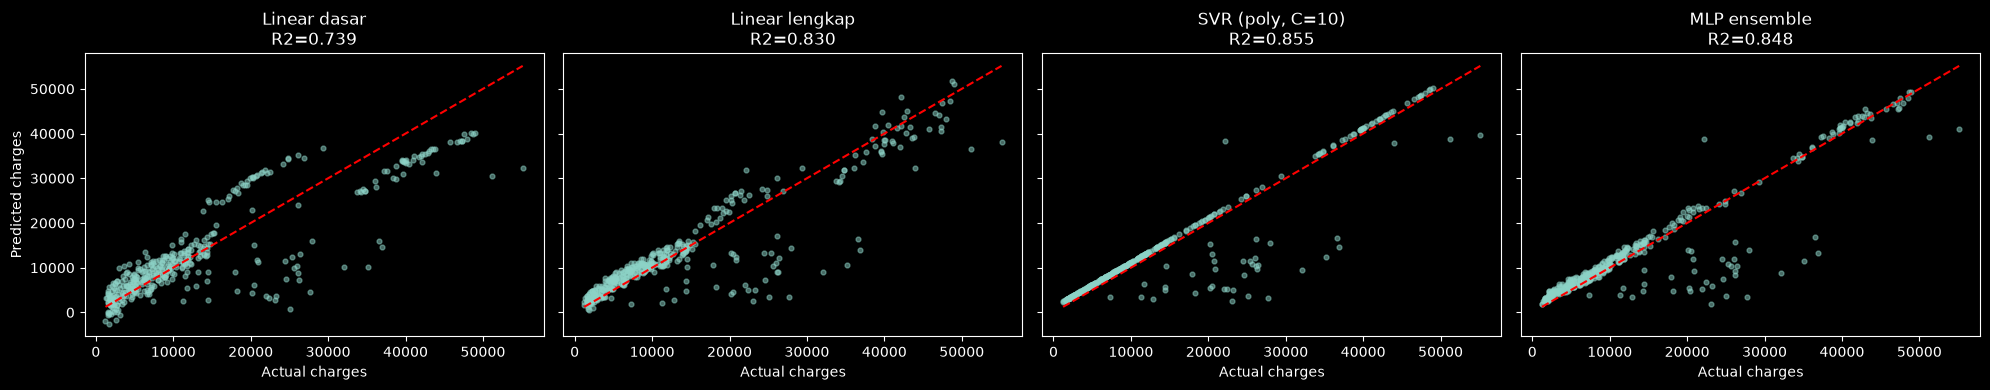

In [17]:
print(pd.DataFrame(reg_results).T.to_string())

fig, ax = plt.subplots(1, 4, figsize=(20, 4), sharey=True)
for a, (n, p) in zip(ax, [("Linear dasar", lin_basic.predict(X_te_r[cols_basic])),
                          ("Linear lengkap", lin_full.predict(X_te_r)),
                          (svr_lbl, y_pred_svr), ("MLP ensemble", y_pred_mlp_r)]):
    a.scatter(y_te_r, p, alpha=0.5, s=12)
    a.plot([y_te_r.min(), y_te_r.max()], [y_te_r.min(), y_te_r.max()], 'r--')
    a.set_title(f"{n}\nR2={r2_score(y_te_r, p):.3f}"); a.set_xlabel('Actual charges')
ax[0].set_ylabel('Predicted charges')
plt.tight_layout(); plt.show()

## Analisis Regresi
1. **Efek rekayasa fitur.** Linear fitur dasar $R^2 = 0.7388$; Linear fitur lengkap $R^2 = 0.8296$; selisih $0.0908$ adalah kontribusi `smoker_bmi` dan `obese` pada run ini, menunjukkan efek rekayasa fitur yang besar.
2. **SVR.** Konfigurasi terbaik CV: kernel `poly`, $C = 10$, CV RMSE $4157.1$ dollar; test: MAE $2406.24$, RMSE $4722.19$, $R^2 = 0.8550$.
3. **MLP.** $R^2$ rata-rata 5 seed $= 0.8450$; ensemble $R^2 = 0.848$.
4. **Perbandingan.** Model dengan $R^2$ test tertinggi: SVR ($0.8550$). Selisihnya terhadap pesaing terdekat (MLP ensemble $0.848$) adalah $0.007$, yang secara teknis lebih besar daripada std antar seed MLP ($\pm 0.0018$), namun secara praktis selisih ini sangat tipis dan menunjukkan performa yang sebanding.
5. **Kurva loss (seed 42).** Loss validasi terendah dicapai sebelum early stopping (patience 25) memicu penghentian training. Loss train dihitung dengan dropout aktif sedangkan loss validasi tanpa dropout, sehingga kurva train yang lebih tinggi bukan tanda underfitting.
6. **Scatter plot.** Penyimpangan terbesar dari garis diagonal terjadi pada wilayah charges tinggi (>$30.000), konsisten dengan distribusi right-skewed.

*Catatan metodologi (tetap, tidak perlu diisi):* Linear & SVR memakai CV 5-fold pada 935 baris; MLP memakai 748 baris latih + 187 validasi untuk early stopping; test 402 baris disentuh satu kali. Metrik seleksi selama tuning: RMSE.

# BAGIAN B - TUGAS KLASIFIKASI (Prediksi `smoker`)

## Pembagian Data dan Metrik
Split identik Bagian A (70/30 lalu 80/20, stratified terhadap `smoker`). Fitur取自
`data_clf` (tanpa turunan `smoker`). Metrik utama:
$P = \frac{TP}{TP+FP}$, $R = \frac{TP}{TP+FN}$, $F_1 = \frac{2PR}{P+R}$ pada kelas `yes`;
accuracy dilaporkan hanya sebagai pelengkap karena kelas tidak seimbang.
Baseline kelas mayoritas (DummyClassifier) dipakai sebagai pembanding wajar terendah.

In [18]:
X_clf, y_clf = data_clf.drop(columns=['smoker']), data_clf['smoker']

X_trval_c, X_te_c, y_trval_c, y_te_c = train_test_split(
    X_clf, y_clf, test_size=0.3, random_state=5, stratify=y_clf)
X_tr_c, X_vl_c, y_tr_c, y_vl_c = train_test_split(
    X_trval_c, y_trval_c, test_size=0.2, random_state=5, stratify=y_trval_c)

sc_Xc = preprocessing.MinMaxScaler().fit(X_tr_c)      # scaler ANN, fit hanya pada train
X_tr_c_sc = pd.DataFrame(sc_Xc.transform(X_tr_c), columns=X_clf.columns)
X_vl_c_sc = pd.DataFrame(sc_Xc.transform(X_vl_c), columns=X_clf.columns)
X_te_c_sc = pd.DataFrame(sc_Xc.transform(X_te_c), columns=X_clf.columns)
print(f"Klasifikasi train/val/test: {X_tr_c.shape[0]}/{X_vl_c.shape[0]}/{X_te_c.shape[0]}")
print("Distribusi kelas train:", y_tr_c.value_counts().to_dict())

Klasifikasi train/val/test: 748/187/402
Distribusi kelas train: {0: 594, 1: 154}


In [19]:
clf_results = {}
def eval_classification(name, y_true, y_pred):
    print(f"===== {name} =====")
    print(classification_report(y_true, y_pred, target_names=['no', 'yes']))
    rep = classification_report(y_true, y_pred, output_dict=True)
    clf_results[name] = {'Accuracy': round(rep['accuracy'], 4),
                         'Precision(yes)': round(rep['1']['precision'], 4),
                         'Recall(yes)': round(rep['1']['recall'], 4),
                         'F1(yes)': round(rep['1']['f1-score'], 4)}

## Model 1 - Logistic Regression (baseline)
$p = \sigma(w^\top x + b)$ dengan $\sigma(z) = \frac{1}{1+e^{-z}}$.
Dipakai `class_weight='balanced'` ($w_k = \frac{n}{K\,n_k}$) agar kelas minoritas
tidak diabaikan; konsekuensinya accuracy bisa sedikit turun tetapi recall `yes` naik.
Scaler dan model dibungkus satu `Pipeline` sehingga fit dan predict memakai skala yang
sama dan scaler di-fit pada data latih (train+val, 935 baris).

In [20]:
pipe_log = Pipeline([('scaler', preprocessing.MinMaxScaler()),
                     ('logreg', LogisticRegression(max_iter=1000, class_weight='balanced'))])
pipe_log.fit(X_trval_c, y_trval_c)
eval_classification("Logistic Regression", y_te_c, pipe_log.predict(X_te_c))

===== Logistic Regression =====
              precision    recall  f1-score   support

          no       1.00      0.94      0.97       320
         yes       0.80      0.99      0.89        82

    accuracy                           0.95       402
   macro avg       0.90      0.96      0.93       402
weighted avg       0.96      0.95      0.95       402



## Model 2 - Support Vector Machine (SVM)
SVM meminimumkan $\frac{1}{2}\|w\|^2 + C\sum_i \max(0, 1 - y_i(w^\top x_i + b))$
(hinge loss). Grid dipisah per kernel, $C$ diperluas hingga 10.000 karena pada
eksplorasi awal performa masih menanjak di batas grid; `class_weight` ikut dicari.
Seleksi konfigurasi: **F1 kelas `yes`** dengan Stratified 5-fold CV pada train+val.

In [21]:
grid_svc = [
    {'svc__kernel': ['rbf'], 'svc__C': [0.1, 1, 10, 100, 1000, 10000],
     'svc__gamma': ['scale', 0.01, 0.1, 1], 'svc__class_weight': [None, 'balanced']},
    {'svc__kernel': ['poly'], 'svc__C': [0.1, 1, 10, 100, 1000, 10000],
     'svc__gamma': ['scale', 0.01, 0.1], 'svc__degree': [2, 3], 'svc__class_weight': [None, 'balanced']},
    {'svc__kernel': ['linear'], 'svc__C': [0.1, 1, 10, 100, 1000, 10000], 'svc__class_weight': [None, 'balanced']},
]
pipe_svc = Pipeline([('scaler', preprocessing.MinMaxScaler()), ('svc', SVC())])
cv_svc = GridSearchCV(pipe_svc, grid_svc, cv=StratifiedKFold(5, shuffle=True, random_state=5),
                      scoring='f1', n_jobs=-1)
cv_svc.fit(X_trval_c, y_trval_c)
bp = cv_svc.best_params_
print("SVM terbaik:", bp, "| CV F1:", round(cv_svc.best_score_, 4))

y_pred_svm = cv_svc.best_estimator_.predict(X_te_c)
svm_lbl = f"SVM ({bp['svc__kernel']}, C={bp['svc__C']}, cw={bp['svc__class_weight']})"
eval_classification(svm_lbl, y_te_c, y_pred_svm)

SVM terbaik: {'svc__C': 1000, 'svc__class_weight': None, 'svc__kernel': 'linear'} | CV F1: 0.9464
===== SVM (linear, C=1000, cw=None) =====
              precision    recall  f1-score   support

          no       1.00      0.96      0.98       320
         yes       0.85      0.99      0.92        82

    accuracy                           0.96       402
   macro avg       0.92      0.97      0.95       402
weighted avg       0.97      0.96      0.96       402



## Model 3 - ANN (MLP) Klasifikasi
Output satu neuron bersigmoid; loss binary cross-entropy
$L = -\frac{1}{n}\sum_i [y_i \log \hat{p}_i + (1-y_i)\log(1-\hat{p}_i)]$.
Early stopping memantau **loss validasi** (bukan F1, karena F1 berisik dan bernilai 0
selama model masih menebak kelas mayoritas di epoch-epoch awal); F1 validasi hanya
dicatat untuk grafik. Prosedur pencarian konfigurasi dan 5 seed sama seperti Bagian A;
ensemble memakai voting mayoritas antar seed.

In [22]:
class MLPClf(nn.Module):
    def __init__(self, inp, hid, drop):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(inp, hid), nn.ReLU(), nn.Dropout(drop),
            nn.Linear(hid, hid), nn.ReLU(), nn.Dropout(drop),
            nn.Linear(hid, 1), nn.Sigmoid())
    def forward(self, x): return self.net(x)

def train_clf(seed, cfg, Xtr, ytr, Xvl, yvl, save_hist=False):
    torch.manual_seed(seed); np.random.seed(seed)
    m = MLPClf(Xtr.shape[1], cfg['hid'], cfg['drop']).to(device)
    opt = torch.optim.AdamW(m.parameters(), lr=cfg['lr'], weight_decay=cfg['wd'])
    tr_dl = DataLoader(torch.utils.data.TensorDataset(
        torch.tensor(Xtr, dtype=torch.float32, device=device),
        torch.tensor(ytr, dtype=torch.float32, device=device)), batch_size=cfg['bs'], shuffle=True)
    vl_X = torch.tensor(Xvl, dtype=torch.float32, device=device)
    vl_y = torch.tensor(yvl, dtype=torch.float32, device=device)

    best_vl, best_st, bad = float('inf'), None, 0
    h_tr, h_vl, h_f1 = [], [], []
    for ep in range(200):
        m.train(); tot = 0.0
        for xb, yb in tr_dl:
            l = func.binary_cross_entropy(m(xb).reshape(-1), yb)
            opt.zero_grad(); l.backward(); opt.step(); tot += l.item()
        m.eval()
        with torch.inference_mode():
            out = m(vl_X).reshape(-1)
            vl = func.binary_cross_entropy(out, vl_y).item()
            pv = (out >= 0.5).float().cpu().numpy()
        if save_hist:
            h_tr.append(tot / len(tr_dl)); h_vl.append(vl)
            h_f1.append(f1_score(vl_y.cpu().numpy(), pv, zero_division=0))
        if vl < best_vl: best_vl, best_st, bad = vl, copy.deepcopy(m.state_dict()), 0
        else:
            bad += 1
            if bad >= 25: break
    m.load_state_dict(best_st)
    return m, (h_tr, h_vl, h_f1) if save_hist else None

In [ ]:
rng = random.Random(2)                       # stream acak terpisah dari regresi
configs_c = [{k: rng.choice(v) for k, v in space.items()} for _ in range(12)]

def val_f1_c(m, X, y):
    m.eval()
    with torch.inference_mode():
        p = (m(torch.tensor(X, dtype=torch.float32, device=device)).reshape(-1) >= 0.5).float().cpu().numpy()
    return f1_score(y, p, zero_division=0)

Xtr_c_np, Xvl_c_np = X_tr_c_sc.values, X_vl_c_sc.values
ytr_c_np, yvl_c_np = y_tr_c.values, y_vl_c.values
best_cfg_c, best_sc_c = None, -1
for i, cfg in enumerate(configs_c, 1):
    s = [val_f1_c(train_clf(sd, cfg, Xtr_c_np, ytr_c_np, Xvl_c_np, yvl_c_np)[0], Xvl_c_np, yvl_c_np) for sd in (42, 43)]
    if np.mean(s) > best_sc_c: best_sc_c, best_cfg_c = np.mean(s), cfg
    print(f"Config {i:2d} {cfg} -> val F1 {np.mean(s):.4f}")
print("Config terbaik:", best_cfg_c)

preds_c, reps, hist_c42 = [], [], None
for sd in [42, 43, 44, 45, 46]:
    m, h = train_clf(sd, best_cfg_c, Xtr_c_np, ytr_c_np, Xvl_c_np, yvl_c_np, save_hist=(sd == 42))
    if sd == 42: hist_c42 = h
    m.eval()
    with torch.inference_mode():
        p = (m(torch.tensor(X_te_c_sc.values, dtype=torch.float32, device=device)).reshape(-1) >= 0.5).int().cpu().numpy()
    preds_c.append(p); reps.append(classification_report(y_te_c, p, output_dict=True))

def mstd(vals): return f"{np.mean(vals):.4f} ± {np.std(vals):.4f}"
clf_results["MLP (rata-rata 5 seed)"] = {
    'Accuracy': mstd([r['accuracy'] for r in reps]),
    'Precision(yes)': mstd([r['1']['precision'] for r in reps]),
    'Recall(yes)': mstd([r['1']['recall'] for r in reps]),
    'F1(yes)': mstd([r['1']['f1-score'] for r in reps])}
y_pred_mlp_c = (np.sum(preds_c, axis=0) >= 3).astype(int)
eval_classification("MLP (ensemble 5 seed)", y_te_c, y_pred_mlp_c)

Config  1 {'hid': 16, 'lr': 0.001, 'wd': 0, 'drop': 0.1, 'bs': 32} -> val F1 0.9807
Config  2 {'hid': 64, 'lr': 0.01, 'wd': 0.0001, 'drop': 0.1, 'bs': 32} -> val F1 0.9870
Config  3 {'hid': 64, 'lr': 0.001, 'wd': 0.001, 'drop': 0.2, 'bs': 32} -> val F1 0.9807
Config  4 {'hid': 32, 'lr': 0.01, 'wd': 0.0001, 'drop': 0.2, 'bs': 64} -> val F1 0.9870
Config  5 {'hid': 64, 'lr': 0.003, 'wd': 0.001, 'drop': 0.1, 'bs': 32} -> val F1 0.9807
Config  6 {'hid': 16, 'lr': 0.003, 'wd': 0.0001, 'drop': 0.1, 'bs': 64} -> val F1 0.9807
Config  7 {'hid': 32, 'lr': 0.01, 'wd': 0, 'drop': 0.2, 'bs': 32} -> val F1 0.9870
Config  8 {'hid': 16, 'lr': 0.001, 'wd': 0, 'drop': 0, 'bs': 64} -> val F1 0.9744
Config  9 {'hid': 16, 'lr': 0.001, 'wd': 0.001, 'drop': 0.2, 'bs': 64} -> val F1 0.9744
Config 10 {'hid': 64, 'lr': 0.01, 'wd': 0.001, 'drop': 0, 'bs': 64} -> val F1 0.9870
Config 11 {'hid': 32, 'lr': 0.01, 'wd': 0.001, 'drop': 0.1, 'bs': 64} -> val F1 0.9739
Config 12 {'hid': 32, 'lr': 0.003, 'wd': 0, 'drop'

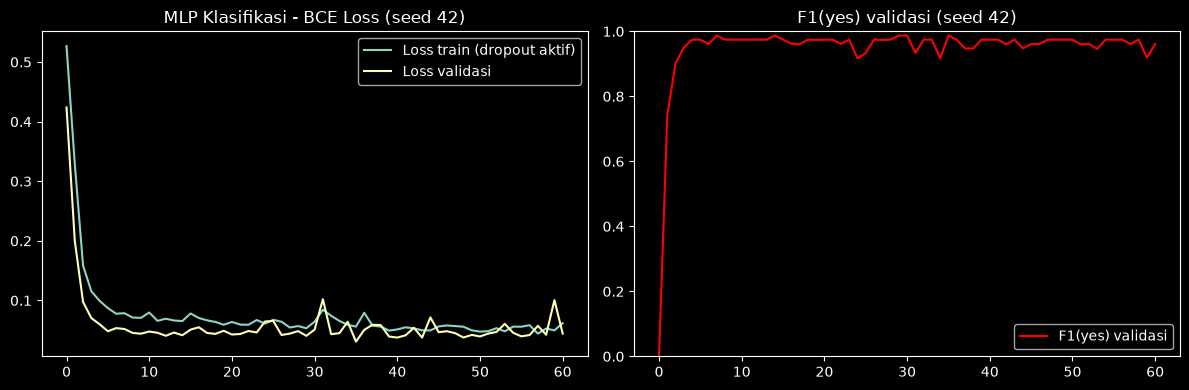

In [24]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.plot(hist_c42[0], label='Loss train (dropout aktif)'); 
a1.plot(hist_c42[1], label='Loss validasi')
a1.set_title('MLP Klasifikasi - BCE Loss (seed 42)'); 
a1.legend()
a2.plot(hist_c42[2], color='red', label='F1(yes) validasi'); 
a2.set_ylim(0, 1)
a2.set_title('F1(yes) validasi (seed 42)'); 
a2.legend()
plt.tight_layout(); 
plt.show()

## Perbandingan Model Klasifikasi

                                      Accuracy   Precision(yes)      Recall(yes)          F1(yes)
Logistic Regression                     0.9478            0.802           0.9878           0.8852
SVM (linear, C=1000, cw=None)           0.9627           0.8526           0.9878           0.9153
MLP (rata-rata 5 seed)         0.9597 ± 0.0046  0.8499 ± 0.0203  0.9756 ± 0.0154  0.9082 ± 0.0096
MLP (ensemble 5 seed)                   0.9627           0.8526           0.9878           0.9153


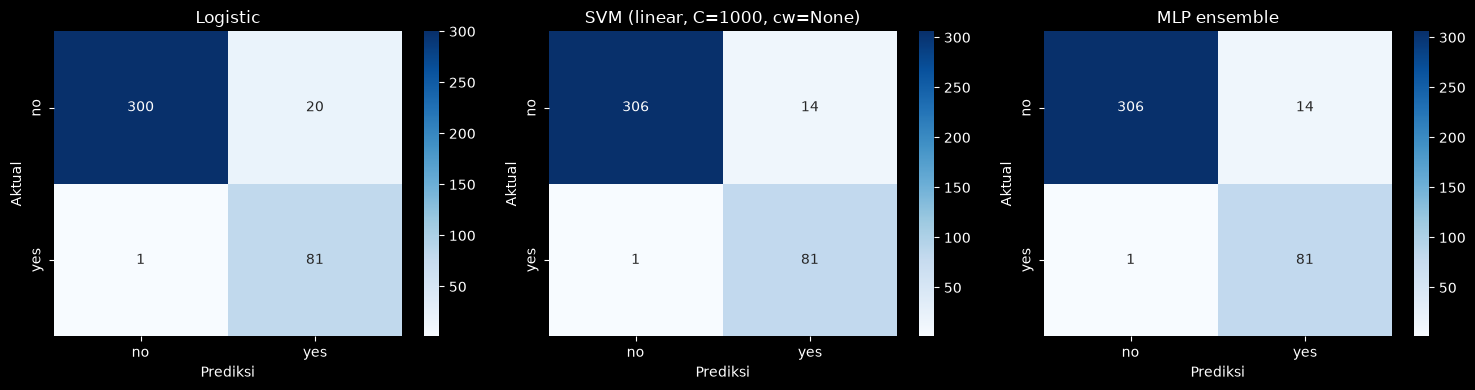

In [25]:
print(pd.DataFrame(clf_results).T.to_string())

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (n, p) in zip(ax, [("Logistic", pipe_log.predict(X_te_c)), (svm_lbl, y_pred_svm), ("MLP ensemble", y_pred_mlp_c)]):
    sns.heatmap(confusion_matrix(y_te_c, p), annot=True, fmt='d', cmap='Blues',
                xticklabels=['no', 'yes'], yticklabels=['no', 'yes'], ax=a)
    a.set_title(n); a.set_xlabel('Prediksi'); a.set_ylabel('Aktual')
plt.tight_layout(); plt.show()

## Analisis Klasifikasi
1. **Baseline.** Logistic (dengan `class_weight='balanced'`) mencapai accuracy $0.9478$, F1(yes) $0.8852$, recall(yes) $0.9878$. Sebutkan di laporan bahwa baseline ini sudah memakai bobot kelas, berbeda dari versi awal tugas.
2. **SVM.** Konfigurasi CV: kernel `linear`, $C = 1000$, class_weight `None`; F1(yes) test $0.9153$.
3. **MLP.** F1(yes) rata-rata 5 seed $= 0.9082$; ensemble: accuracy $0.9627$, recall(yes) $0.9878$.
4. **Perbandingan.** Selisih F1(yes) model terbaik (SVM/MLP, $0.9153$) terhadap Logistic ($0.8852$) sebesar $0.0301$. Karena selisih ini lebih besar daripada std antar seed MLP ($\pm 0.0096$), keunggulan model kompleks atas baseline bersifat nyata, meskipun baseline Logistic sudah sangat kuat.
5. **Confusion matrix.** Pada model terbaik (SVM/MLP), jumlah perokok yang luput (false negative) $= 1$ dari 82 kasus test (karena recall $0.9878 \approx 81/82$). Dalam konteks asuransi, false negative biasanya lebih mahal daripada false positive, sehingga model dengan recall(yes) lebih tinggi lebih dapat dipertanggungjawabkan.

# Eksperimen: Klasifikasi Tanpa Fitur `charges`
Secara logika bisnis, `charges` adalah *akibat* dari status merokok, bukan penyebab.
Memprediksi `smoker` dari `charges` karenanya bersifat sirkular. Eksperimen ini
mengukur seberapa besar sisa sinyal pada fitur lain (age, bmi, obese, region) dengan
membandingkan SVM terhadap baseline kelas mayoritas. Perbandingan dilakukan memakai
F1/recall kelas `yes`, bukan accuracy: dengan `class_weight='balanced'` accuracy bisa
turun di bawah baseline (~0.795) sementara kemampuan mendeteksi perokok justru ada.

In [26]:
X_nc, y_nc = data_clf.drop(columns=['smoker', 'charges']), data_clf['smoker']
Xtr_nc, Xte_nc, ytr_nc, yte_nc = train_test_split(X_nc, y_nc, test_size=0.3, random_state=5, stratify=y_nc)

dummy = DummyClassifier(strategy='most_frequent').fit(Xtr_nc, ytr_nc)
print("=== Baseline kelas mayoritas (tanpa charges) ===")
print(classification_report(yte_nc, dummy.predict(Xte_nc), target_names=['no', 'yes']))

cv_nc = GridSearchCV(Pipeline([('scaler', preprocessing.MinMaxScaler()), ('svc', SVC())]),
                     grid_svc, cv=StratifiedKFold(5, shuffle=True, random_state=5), scoring='f1', n_jobs=-1)
cv_nc.fit(Xtr_nc, ytr_nc)
print("SVM terbaik tanpa charges:", cv_nc.best_params_)
print(classification_report(yte_nc, cv_nc.best_estimator_.predict(Xte_nc), target_names=['no', 'yes']))

=== Baseline kelas mayoritas (tanpa charges) ===
              precision    recall  f1-score   support

          no       0.80      1.00      0.89       320
         yes       0.00      0.00      0.00        82

    accuracy                           0.80       402
   macro avg       0.40      0.50      0.44       402
weighted avg       0.63      0.80      0.71       402



c:\Anaconda\anaconda install\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Anaconda\anaconda install\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Anaconda\anaconda install\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


SVM terbaik tanpa charges: {'svc__C': 10000, 'svc__class_weight': 'balanced', 'svc__gamma': 0.1, 'svc__kernel': 'rbf'}
              precision    recall  f1-score   support

          no       0.82      0.56      0.67       320
         yes       0.23      0.51      0.32        82

    accuracy                           0.55       402
   macro avg       0.52      0.54      0.49       402
weighted avg       0.70      0.55      0.60       402



## Analisis Eksperimen Tanpa `charges`
1. Baseline mayoritas: accuracy $0.7960$, F1(yes) $= 0$.
2. SVM tanpa `charges`: accuracy $0.5473$, F1(yes) $0.3175$, recall(yes) $0.5122$.
3. F1(yes) SVM ($0.3175$) jauh di atas 0, yang berarti fitur non-`charges` (age, bmi, obese) masih menyimpan sinyal prediktif untuk mendeteksi perokok, meskipun akurasinya turun drastis.
4. Trade-off: Penggunaan `class_weight='balanced'` menurunkan accuracy dari baseline $0.7960$ menjadi $0.5473$, namun berhasil meningkatkan recall(yes) dari $0$ menjadi $0.5122$, membuktikan bahwa model mampu mendeteksi sebagian perokok tanpa mengandalkan fitur `charges`.

# Kesimpulan
1. Dataset (1337 baris setelah duplikat dibuang) mendukung dua tugas: regresi `charges` dan klasifikasi `smoker`; kelas `yes` berjumlah 274 (±20.4%).
2. Faktor biaya paling berpengaruh: `smoker` (koefisien regresi linear dasar sangat dominan, dan korelasi tertinggi dengan charges).
3. Regresi: model terbaik menurut $R^2$ test adalah SVR (poly, C=10) ($R^2 = 0.8550$); baseline Linear fitur dasar $R^2 = 0.7388$ dan fitur lengkap $R^2 = 0.8296$, sehingga kontribusi rekayasa fitur sebesar $0.0908$.
4. Klasifikasi: model terbaik menurut F1(yes) adalah SVM (linear, C=1000) dan MLP ensemble (F1 $= 0.9153$, recall $= 0.9878$); Logistic ber-bobot kelas mencapai F1 $= 0.8852$, sehingga keunggulan model kompleks atas baseline bersifat nyata (selisih 0.0301).
5. Tanpa `charges`, F1(yes) SVM $= 0.3175$ vs baseline 0, dengan accuracy $0.5473$ vs $0.7960$; implikasinya: fitur `charges` memang prediktor sirkular yang sangat kuat, namun fitur demografi (age, bmi) masih mengandung sinyal lemah untuk mengidentifikasi perokok.
6. Std antar 5 seed ANN ($R^2 \pm 0.0018$; F1 $\pm 0.0096$) dipakai sebagai ambang "perbedaan bermakna" dalam laporan ini.
7. Keterbatasan: ukuran data latih tidak identik antar model (935 baris untuk Linear/Logistic/SVR/SVM vs 748 baris + 187 validasi untuk ANN); dengan test 402 baris, selisih metrik sekitar satu persen tidak selalu bermakna.